# 03 · Engineering drawings SFT: GLM 5.3 Flash vision LoRA on 480 drawings

Same recipe as the CORD fine-tune: each training row is `[drawing image, the dataset's instruction] → compact gold JSON`, trained on the serverless vision LoRA path and scored on the 60 test drawings inside the training session. The model is promoted automatically (`promoted_models.json`).

- **Data:** all 480 train drawings (≈2,000 tokens each including the image)
- **LoRA:** rank 16, learning rate 1e-4, 2 epochs, batch 8 → 120 steps
- **Eval:** the tuned model gets only the instruction (no schema example), exactly like training

Compared against the one-shot baseline and the best harness.

In [1]:
import asyncio, json, os, sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "eng_common.py").exists():
    HERE = Path("experiments/eng-drawings-extraction").resolve()
os.chdir(HERE)
sys.path.insert(0, str(HERE))

import eng_common as c
import eng_report as rep
rep.fv.apply_theme()
print({s: len(c.load_split(s)) for s in ("train", "validation", "test")}, "· API key set:", bool(os.getenv("FIREWORKS_API_KEY")))
import fw_utils as fw

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 480, 'validation': 60, 'test': 60} · API key set: True


## Train + score (background job, ~1–1.5 h)

In [2]:
fw.start("glm_sft", ["eng_sft.py", "--tag", "glm_sft", "--epochs", "2", "--batch-size", "8",
                        "--lora-rank", "16", "--learning-rate", "1e-4"])

glm_sft already done: results/results_glm_sft.jsonl exists. Delete it to run again.


In [3]:
fw.watch("glm_sft")

                                  output_model_id=model_id, base_model=BASE_MODEL)
                                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/fireworks/training/sdk/fireworks_client.py", line 726, in promote_session_checkpoint
    raise RuntimeError(
    ...<4 lines>...
    )
RuntimeError: ERROR: Failed to promote session checkpoint 'run-cc21d6bf58dd48618870a2ec368cfe19-eng-tuned-df0e448b' (HTTP 500)
  Cause: failed to sync regional sampler checkpoint "pyroworks/run-cc21d6bf58dd48618870a2ec368cfe19/eng-tuned-df0e448b" to durable storage: error syncing regional checkpoint through service: rpc error: code = Unavailable desc = regional checkpoint service default/regional-checkpoint-service request failed: the server is currently unable to handle the request (post services http:regional-checkpoint-service:http)
  Solution: Retry checkpoint promotion. If the error persists, contact Fireworks s

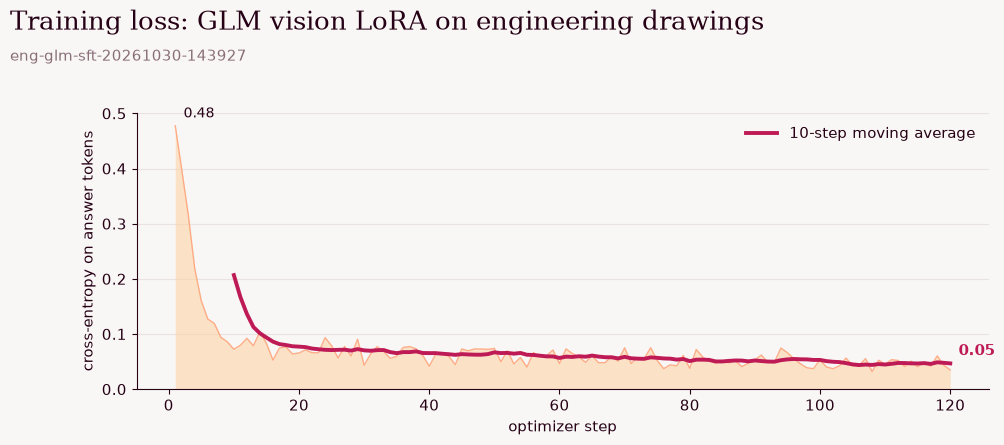

In [4]:
runs = [p for p in sorted((HERE / "sft_logs").glob("eng-glm-sft-*/metrics.jsonl")) if p.read_text().strip()]
if runs:
    rep.fv.loss_curve(runs[-1], "Training loss: GLM vision LoRA on engineering drawings", runs[-1].parent.name, save="loss_curve")

## Results

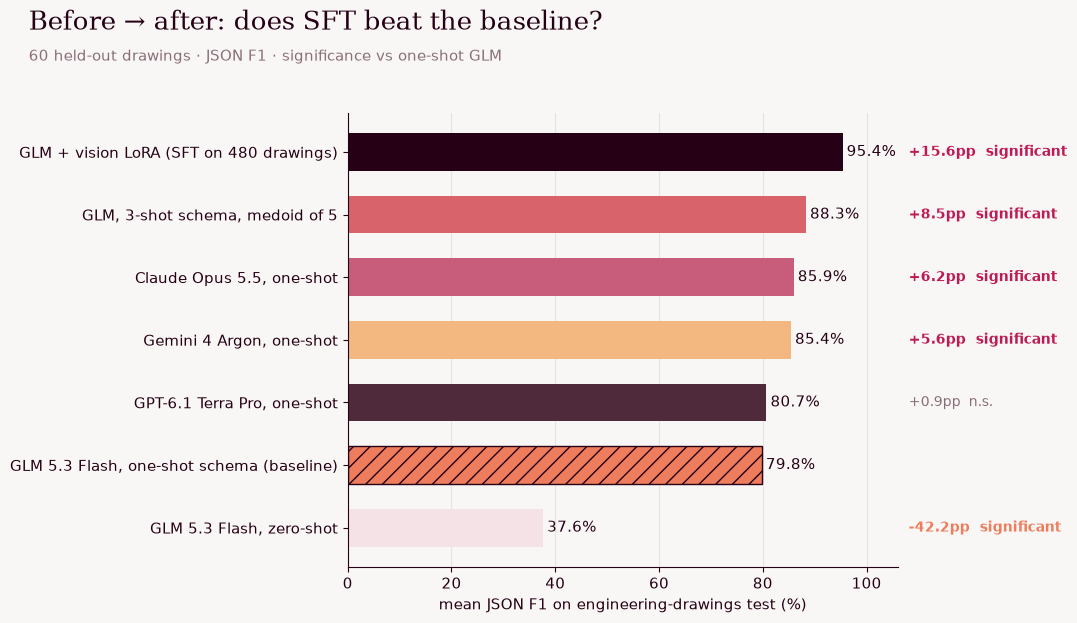

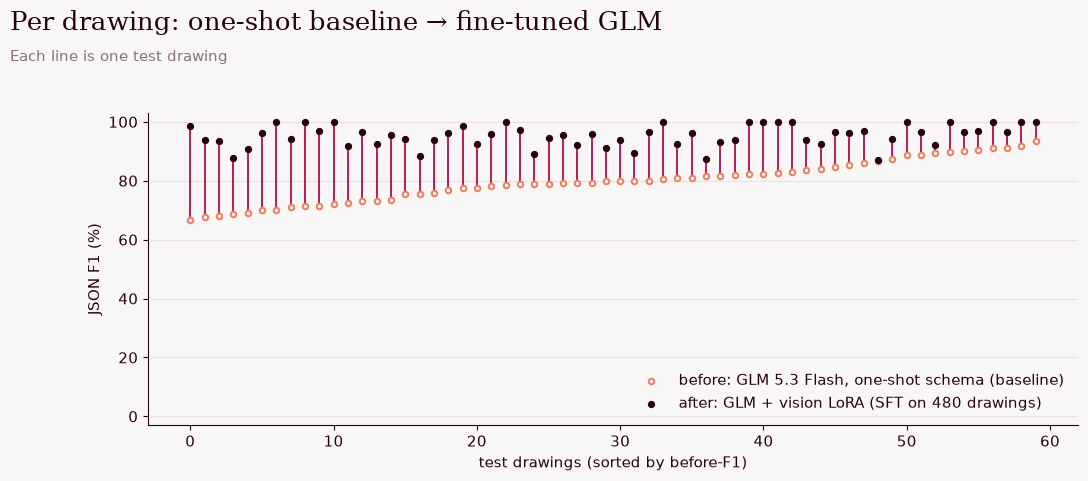

In [5]:
rep.leaderboard(["glm_zero", "glm_oneshot", "glm_fewshot_vote", "glm_sft", "gemini4_oneshot", "opus55_oneshot", "gpt61_oneshot"],
                "glm_oneshot", "Before → after: does SFT beat the baseline?", "60 held-out drawings · JSON F1 · significance vs one-shot GLM", save="leaderboard")
rep.before_after("glm_oneshot", "glm_sft", "Per drawing: one-shot baseline → fine-tuned GLM", "Each line is one test drawing", save="per_drawing")

In [6]:
rep.significance_table([("glm_sft", "glm_oneshot"), ("glm_sft", "glm_fewshot_vote"), ("glm_sft", "gemini4_oneshot"), ("glm_sft", "opus55_oneshot")])

,drawings,fields,F1 a,F1 b,ΔF1 pp,fields only a,fields only b,McNemar p (fields),bootstrap 95% CI (drawings),significant,notes
pair,,,,,,,,,,,
"GLM + vision LoRA (SFT on 480 drawings) vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,95.4%,79.8%,15.6,327,7,5.04e-87,"[+13.7, +17.4]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on 480 drawings) vs GLM, 3-shot schema, medoid of 5",60,1791,95.4%,88.3%,7.1,145,5,8.58e-37,"[+6.0, +8.1]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on 480 drawings) vs Gemini 4 Argon, one-shot",60,1791,95.4%,85.4%,10.0,223,58,5.56e-24,"[+8.3, +11.6]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on 480 drawings) vs Claude Opus 5.5, one-shot",60,1791,95.4%,85.9%,9.4,224,55,2.29e-25,"[+7.5, +11.3]",True,GAIN holds under both tests


,drawings,fields,F1 a,F1 b,ΔF1 pp,fields only a,fields only b,McNemar p (fields),bootstrap 95% CI (drawings),significant,notes
pair,,,,,,,,,,,
"GLM + vision LoRA (SFT on 480 drawings) vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,95.4%,79.8%,15.6,327,7,5.04e-87,"[+13.7, +17.4]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on 480 drawings) vs GLM, 3-shot schema, medoid of 5",60,1791,95.4%,88.3%,7.1,145,5,8.58e-37,"[+6.0, +8.1]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on 480 drawings) vs Gemini 4 Argon, one-shot",60,1791,95.4%,85.4%,10.0,223,58,5.56e-24,"[+8.3, +11.6]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on 480 drawings) vs Claude Opus 5.5, one-shot",60,1791,95.4%,85.9%,9.4,224,55,2.29e-25,"[+7.5, +11.3]",True,GAIN holds under both tests


**The two tests in pictures.** McNemar: do the disagreements split like a coin flip? Bootstrap: across 5,000 fake test sets, does the gap stay on one side of zero?

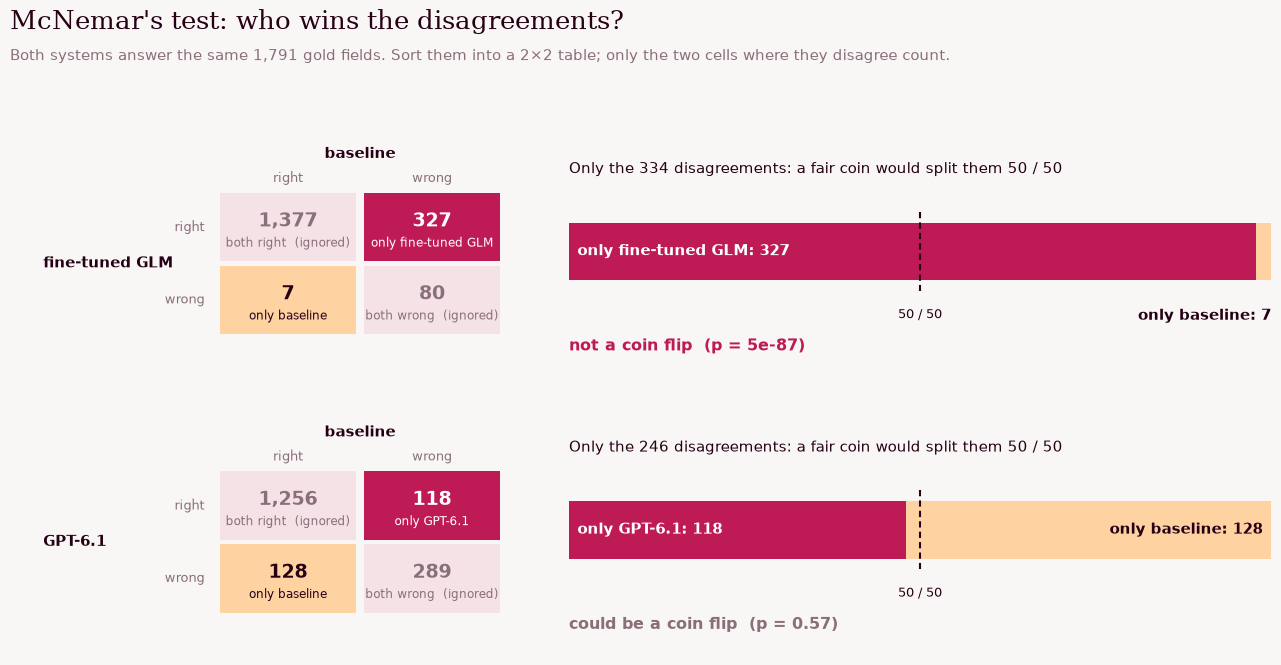

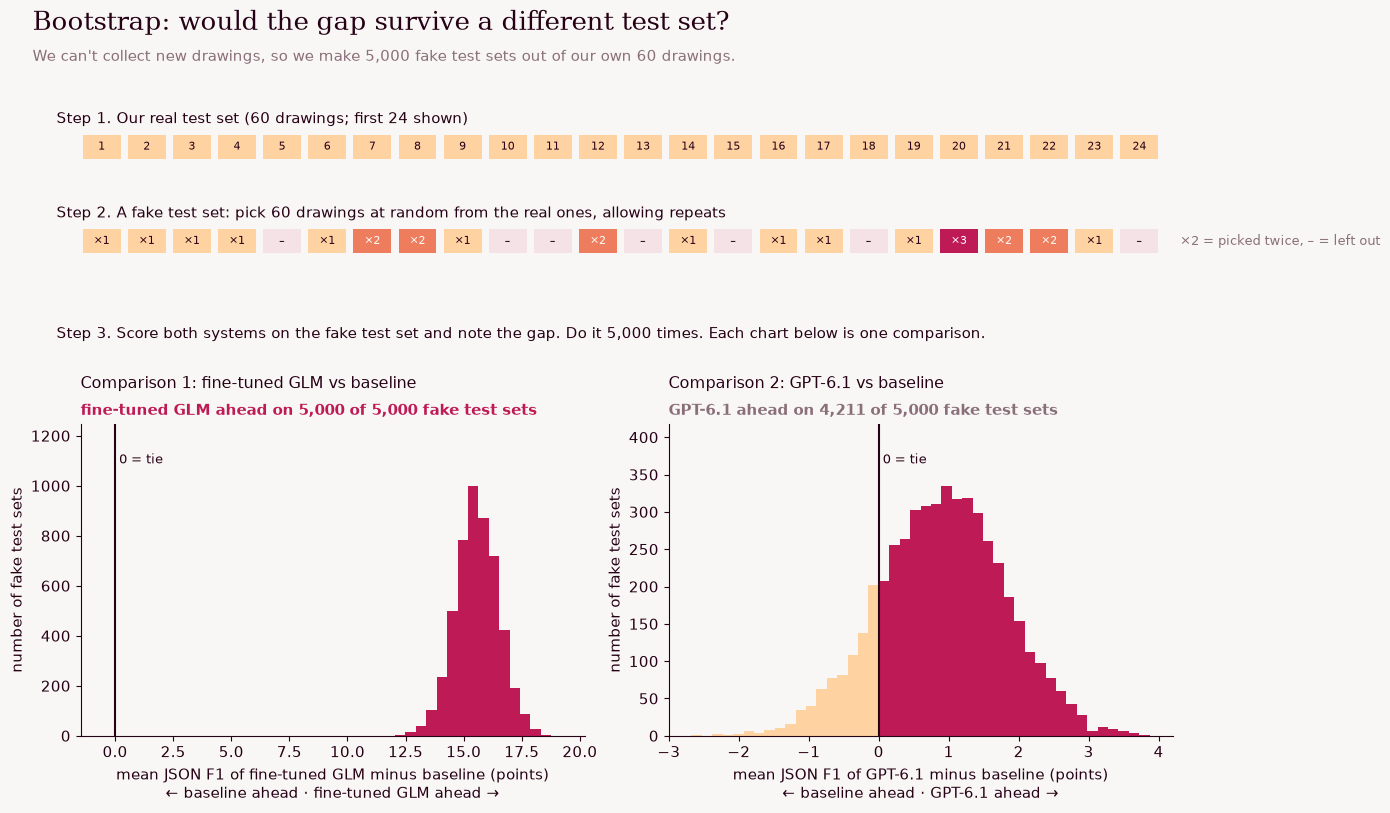

In [7]:
rep.fv.mcnemar_figure(
    [("fine-tuned GLM", "baseline", "not a coin flip", rep.compare("glm_sft", "glm_oneshot")),
     ("GPT-6.1", "baseline", "could be a coin flip", rep.compare("gpt61_oneshot", "glm_oneshot"))],
    unit="gold field", n_items=1791, save="mcnemar_table")
rep.fv.bootstrap_figure(
    [("fine-tuned GLM", "baseline", rep.compare("glm_sft", "glm_oneshot")),
     ("GPT-6.1", "baseline", rep.compare("gpt61_oneshot", "glm_oneshot"))],
    n_clusters=60, cluster="drawing", metric="mean JSON F1", save="bootstrap_resampling")

**Stats.** Field-level McNemar: each of the 2,163 gold fields in the 60 test drawings is right or wrong for each system. Drawing-level bootstrap on mean F1 (resampling drawings). A gain counts only when both are significant.